# Bank churn prediction with a neural network

**Ahmad Hassan** | AI Engineer

A bank wants to know which customers will leave in the next six months, so a retention team can contact them first.
The data holds 10,000 customers (credit score, country, gender, age, tenure, balance, products, card, activity,
salary) and whether they left. The model is a neural network, checked against two standard models.

**Result.** A PyTorch network (32-16-8, Adam, class weights, early stopping), chosen by validation PR-AUC, catches **72.5%** of the customers who left in the test set, and **51%** of the customers it flags really leave (PR-AUC 0.70, ROC-AUC 0.86). The first version's network reached a similar recall with only 39% of its flags right. Gradient boosting does slightly better on the same split (PR-AUC 0.72, 55% of flags right); logistic regression does much worse (0.47).

## What changed from the first version

- **Models were ranked by recall alone at a 0.5 threshold.** Recall can be pushed to 100% by calling everyone a
  churner, so that rule favours whichever model predicts "leaves" most often; the chosen network flagged so many
  customers that only 39% of its alerts were right. Here architectures are compared by PR-AUC on the validation set,
  and the alert threshold is then chosen on validation for at least 70% recall with the best precision.
- **"Overfitting" was judged against oversampled data.** Training recall was measured on SMOTE-resampled rows and
  compared with validation recall on real rows. Here SMOTE is replaced by class weights, and train and validation are
  compared on real data.
- **The SGD network was not really trained** (10 epochs at learning rate 0.001, recall 0.000), so "SGD is worse"
  was an artifact. Every network here trains until its validation loss stops improving (early stopping).
- **There was no benchmark.** A neural network is only worth it if it beats simpler models; logistic regression and
  gradient boosting are now trained on the same split.
- **Some insights contradicted the data**: customers with one product churn far more than those with two (not
  less), and age is the strongest single factor (not "a minor role").
- The network is written in PyTorch. Course instructions ("Complete the code...") and the Colab path were removed.

## 1. The data

In [1]:
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

churn = pd.read_csv("Churn.csv").drop(columns=["RowNumber", "CustomerId", "Surname"])
print(churn.shape, "| missing:", churn.isna().sum().sum(), "| duplicates:", churn.duplicated().sum())
print(f"Customers who left: {churn.Exited.mean():.1%}")
churn.describe().round(1)

(10000, 11) | missing: 0 | duplicates: 0
Customers who left: 20.4%


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,650.5,38.9,5.0,76485.9,1.5,0.7,0.5,100090.2,0.2
std,96.7,10.5,2.9,62397.4,0.6,0.5,0.5,57510.5,0.4
min,350.0,18.0,0.0,0.0,1.0,0.0,0.0,11.6,0.0
25%,584.0,32.0,3.0,0.0,1.0,0.0,0.0,51002.1,0.0
50%,652.0,37.0,5.0,97198.5,1.0,1.0,1.0,100193.9,0.0
75%,718.0,44.0,7.0,127644.2,2.0,1.0,1.0,149388.2,0.0
max,850.0,92.0,10.0,250898.1,4.0,1.0,1.0,199992.5,1.0


In [2]:
rates = {}
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]:
    rates[col] = churn.groupby(col).Exited.agg(["mean", "size"]).rename(columns={"mean": "left", "size": "customers"})
for col, t in rates.items():
    print(col); print(t.assign(left=t.left.round(3)).to_string()); print()
churn["age_band"] = pd.cut(churn.Age, [17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
print(churn.groupby("age_band", observed=True).Exited.mean().round(3).to_string())
churn = churn.drop(columns="age_band")

Geography
            left  customers
Geography                  
France     0.162       5014
Germany    0.324       2509
Spain      0.167       2477

Gender
         left  customers
Gender                  
Female  0.251       4543
Male    0.165       5457

NumOfProducts
                left  customers
NumOfProducts                  
1              0.277       5084
2              0.076       4590
3              0.827        266
4              1.000         60

IsActiveMember
                 left  customers
IsActiveMember                  
0               0.269       4849
1               0.143       5151

HasCrCard
            left  customers
HasCrCard                  
0          0.208       2945
1          0.202       7055

age_band
18-30    0.075
31-40    0.121
41-50    0.340
51-60    0.562
61+      0.248


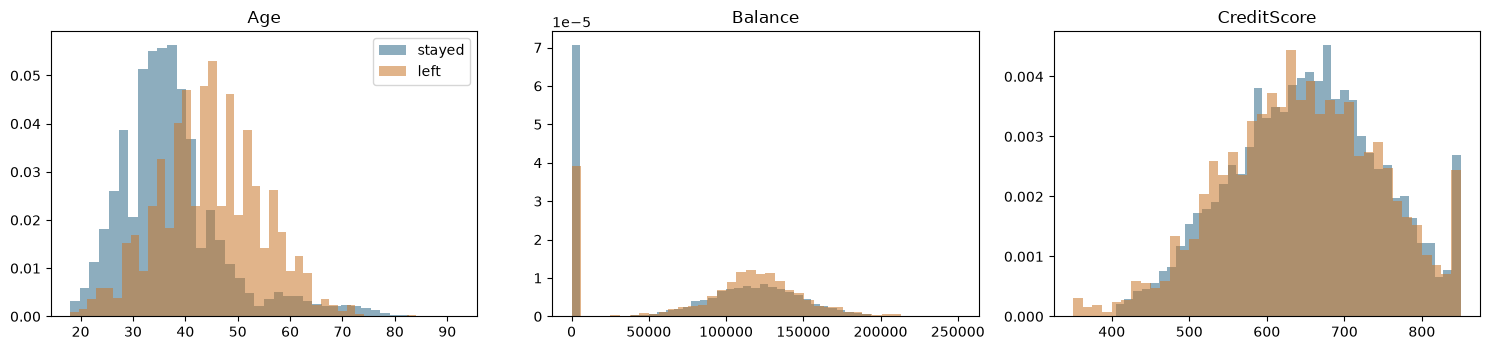

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ["Age", "Balance", "CreditScore"]):
    for v, colour in [(0, "#2f6b8a"), (1, "#c9772b")]:
        a.hist(churn.loc[churn.Exited == v, col], bins=40, alpha=.55, density=True, color=colour, label=["stayed", "left"][v])
    a.set_title(col)
ax[0].legend(); plt.tight_layout(); plt.show()

- **Age** is the clearest signal: about 8% of customers aged 18-30 left, against more than half of those aged 51-60.
- **Products:** one product means about 28% left, two products about 8%; the few customers with three or four
  products almost all left.
- **Inactive members** leave about twice as often as active ones; **Germany** has about twice the churn of France
  or Spain; women leave more often than men.
- About a third of customers have a zero balance.
- Credit score, salary, tenure and having a card make little difference.

## 2. Train, validation and test (60 / 20 / 20, stratified)

In [4]:
X = pd.get_dummies(churn.drop(columns="Exited"), columns=["Geography", "Gender"], drop_first=True, dtype=float)
y = churn.Exited.values
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (scaler.transform(d).astype(np.float32) for d in (X_train, X_val, X_test))
print(f"train {len(y_train)} | validation {len(y_val)} | test {len(y_test)}; features: {list(X.columns)}")

train 6000 | validation 2000 | test 2000; features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


## 3. The neural network

A feed-forward network with ReLU layers, optional dropout, and a single output. The positive class is weighted by
the ratio of stayers to leavers in the loss (instead of creating synthetic customers with SMOTE). Training uses Adam
or SGD with momentum and stops when the validation loss has not improved for 15 epochs, keeping the best weights.

In [5]:
def make_net(layers, dropout):
    mods, d = [], Xtr.shape[1]
    for h in layers:
        mods += [nn.Linear(d, h), nn.ReLU()] + ([nn.Dropout(dropout)] if dropout else [])
        d = h
    return nn.Sequential(*mods, nn.Linear(d, 1))

def train_net(layers, dropout=0.0, optimiser="adam", lr=1e-3, batch=64, max_epochs=300, patience=15, seed=SEED):
    torch.manual_seed(seed)
    net = make_net(layers, dropout)
    opt = torch.optim.Adam(net.parameters(), lr=lr) if optimiser == "adam" else \
        torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((y_train == 0).sum() / (y_train == 1).sum()))
    xt, yt = torch.tensor(Xtr), torch.tensor(y_train, dtype=torch.float32)
    xv, yv = torch.tensor(Xva), torch.tensor(y_val, dtype=torch.float32)
    best, best_state, wait, history = np.inf, None, 0, []
    g = torch.Generator().manual_seed(seed)
    for epoch in range(max_epochs):
        net.train()
        for idx in torch.randperm(len(xt), generator=g).split(batch):
            opt.zero_grad()
            loss_fn(net(xt[idx]).squeeze(1), yt[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            tl = loss_fn(net(xt).squeeze(1), yt).item()
            vl = loss_fn(net(xv).squeeze(1), yv).item()
        history.append((tl, vl))
        if vl < best - 1e-4:
            best, best_state, wait = vl, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    return net, np.array(history)

def proba(net, Xs):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(torch.tensor(Xs)).squeeze(1)).numpy()

In [6]:
configs = {
    "64-32, SGD (momentum)": dict(layers=(64, 32), optimiser="sgd", lr=0.01),
    "64-32, Adam": dict(layers=(64, 32)),
    "64-32, Adam, dropout 0.2": dict(layers=(64, 32), dropout=0.2),
    "32-16-8, Adam": dict(layers=(32, 16, 8)),
    "128-64-32, Adam, dropout 0.3": dict(layers=(128, 64, 32), dropout=0.3),
}
nets, rows = {}, {}
for name, cfg in configs.items():
    net, hist = train_net(**cfg)
    nets[name] = (net, hist)
    p_tr, p_va = proba(net, Xtr), proba(net, Xva)
    rows[name] = {"epochs": len(hist), "train PR-AUC": average_precision_score(y_train, p_tr),
                  "validation PR-AUC": average_precision_score(y_val, p_va), "validation ROC-AUC": roc_auc_score(y_val, p_va)}
board = pd.DataFrame(rows).T.round(3).sort_values("validation PR-AUC", ascending=False)
board

,epochs,train PR-AUC,validation PR-AUC,validation ROC-AUC
"32-16-8, Adam",27.0,0.720,0.678,0.851
"64-32, Adam, dropout 0.2",48.0,0.734,0.675,0.853
"64-32, SGD (momentum)",30.0,0.732,0.672,0.850
"64-32, Adam",27.0,0.719,0.666,0.848
"128-64-32, Adam, dropout 0.3",26.0,0.715,0.662,0.852


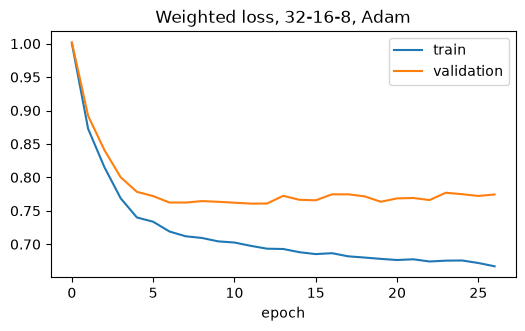

Chosen network: 32-16-8, Adam


In [7]:
best_name = board.index[0]
net, hist = nets[best_name]
plt.figure(figsize=(6, 3.2))
plt.plot(hist[:, 0], label="train"); plt.plot(hist[:, 1], label="validation")
plt.title(f"Weighted loss, {best_name}"); plt.xlabel("epoch"); plt.legend(); plt.show()
print("Chosen network:", best_name)

With early stopping, SGD with momentum learns as well as Adam; the architectures differ by one to two points of PR-AUC,
within run-to-run noise on 2,000 validation customers. Training PR-AUC is about four points above validation, a
modest gap that early stopping keeps from growing.

## 4. Benchmarks on the same split

In [8]:
logit = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y_train)
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, class_weight="balanced",
                                     random_state=SEED).fit(Xtr, y_train)
val = {"neural network": proba(net, Xva), "logistic regression": logit.predict_proba(Xva)[:, 1],
       "gradient boosting": gbm.predict_proba(Xva)[:, 1]}
pd.DataFrame({n: {"validation PR-AUC": average_precision_score(y_val, p), "validation ROC-AUC": roc_auc_score(y_val, p)}
              for n, p in val.items()}).T.round(3)

,validation PR-AUC,validation ROC-AUC
neural network,0.678,0.851
logistic regression,0.455,0.761
gradient boosting,0.684,0.862


## 5. Alert threshold, chosen on validation

The retention team wants to reach most leavers. The threshold is set on the validation set as the highest one that
still catches at least 70% of leavers, which gives the fewest false alarms at that recall.

In [9]:
def threshold_for_recall(y_true, p, target=0.70):
    prec, rec, thr = precision_recall_curve(y_true, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[-1]]

thresholds = {n: threshold_for_recall(y_val, p) for n, p in val.items()}
print({n: round(float(t), 3) for n, t in thresholds.items()})

{'neural network': 0.557, 'logistic regression': 0.48, 'gradient boosting': 0.548}


## 6. The test set, scored once

In [10]:
test = {"neural network": proba(net, Xte), "logistic regression": logit.predict_proba(Xte)[:, 1],
        "gradient boosting": gbm.predict_proba(Xte)[:, 1]}
res = {}
for n, p in test.items():
    pred = p >= thresholds[n]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    res[n] = {"PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
              "recall": tp / (tp + fn), "precision": tp / (tp + fp), "customers flagged": int(pred.sum())}
pd.DataFrame(res).T.round(3)

,PR-AUC,ROC-AUC,recall,precision,customers flagged
neural network,0.699,0.858,0.725,0.513,575.0
logistic regression,0.469,0.777,0.747,0.379,802.0
gradient boosting,0.716,0.869,0.720,0.550,533.0


              precision    recall  f1-score   support

      stayed      0.921     0.824     0.870      1593
        left      0.513     0.725     0.601       407

    accuracy                          0.804      2000
   macro avg      0.717     0.775     0.735      2000
weighted avg      0.838     0.804     0.815      2000



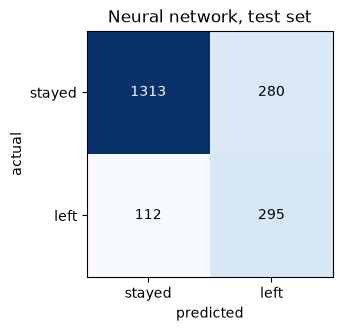

In [11]:
pred = test["neural network"] >= thresholds["neural network"]
print(classification_report(y_test, pred, target_names=["stayed", "left"], digits=3))
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4, 3.2)); plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks([0, 1], ["stayed", "left"]); plt.yticks([0, 1], ["stayed", "left"]); plt.xlabel("predicted"); plt.ylabel("actual")
plt.title("Neural network, test set"); plt.show()

## Conclusions and recommendations

- **The neural network works, but it is not the best tool here.** At about the same recall it is slightly less precise than gradient boosting (51% vs 55% of flags right) and far better than logistic regression (38%); on tabular data like this, a tree ensemble is the stronger and simpler choice.
- **Where to act:** older customers (the churn rate climbs steeply after 40), inactive members, customers in
  Germany, and customers with a single product. Moving one-product customers to a second product is the clearest
  lever in this data: two-product customers leave far less often. Customers with three or four products almost all
  left, which deserves a closer look at what those bundles are.
- **Threshold, not resampling:** class weights and a threshold chosen for the recall the team needs replace SMOTE;
  the trade-off between reaching leavers and wasted calls is set explicitly.

**Limits.** One split of 10,000 customers; the data has no dates, so the model cannot be checked on a later period.